## Imports

In [7]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [8]:
!nvidia-smi

Thu Oct  1 14:15:20 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.71.05              Driver Version: 595.71.05      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A10G                    On  |   00000000:00:1E.0 Off |                    0 |
|  0%   35C    P0             62W /  300W |       3MiB /  23028MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Configure the dataset

In [16]:
!aws s3 sync s3://YOUR-BUCKET/raw/asl_alphabet_train/ /home/ec2-user/SageMaker/asl_alphabet_train/ --quiet

!aws s3 sync s3://YOUR-BUCKET/processed/ /home/ec2-user/SageMaker/asl_preprocessed/  --quiet

In [17]:
# ============================================================
# CONFIGURATION
# ============================================================

BASE_DIR = Path("/home/ec2-user/SageMaker")

RAW_DIR = BASE_DIR / "asl_alphabet_train"

PREPROCESSED_DIR = BASE_DIR / "asl_preprocessed"

MANIFEST_PATH = PREPROCESSED_DIR / "manifest.csv"


# ------------------------------------------------------------
# CHOOSE DATA REPRESENTATION
# ------------------------------------------------------------
#
# "raw"       = original RGB images
# "filtered"  = Gaussian-filtered RGB images
# "edges"     = Canny edge images
#

REPRESENTATION = "raw"


# ------------------------------------------------------------
# IMAGE CONFIGURATION
# ------------------------------------------------------------

IMG_HEIGHT = 200
IMG_WIDTH = 200

if REPRESENTATION == "edges":
    CHANNELS = 1
else:
    CHANNELS = 3

INPUT_SHAPE = (
    IMG_HEIGHT,
    IMG_WIDTH,
    CHANNELS
)


# ------------------------------------------------------------
# CLASS CONFIGURATION
# ------------------------------------------------------------
NUM_CLASSES = 29

# ------------------------------------------------------------
# TRAINING CONFIGURATION
# ------------------------------------------------------------
BATCH_SIZE = 32
EPOCHS = 25

LEARNING_RATE = 0.001


print("Representation:", REPRESENTATION)
print("Input shape:", INPUT_SHAPE)
print("Classes:", NUM_CLASSES)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)

Representation: raw
Input shape: (200, 200, 3)
Classes: 29
Batch size: 32
Epochs: 25


## Verify the manifest

In [18]:
if not MANIFEST_PATH.exists():

    raise FileNotFoundError(
        f"""
manifest.csv was not found:

{MANIFEST_PATH}

Run your dataset splitting/preprocessing notebook cells first.
"""
    )

manifest = pd.read_csv(MANIFEST_PATH)

print("Manifest shape:", manifest.shape)

print("\nColumns:")
print(list(manifest.columns))

print("\nSplits:")
print(
    manifest["split"]
    .value_counts()
)

print("\nNumber of classes:")
print(
    manifest["label"].nunique()
)

print("\nClasses:")
print(
    sorted(manifest["label"].unique())
)

Manifest shape: (87000, 5)

Columns:
['split', 'label', 'original_path', 'filtered_path', 'edge_path']

Splits:
split
train         60900
validation    13050
test          13050
Name: count, dtype: int64

Number of classes:
29

Classes:
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


## Create the 29-class mapping

In [19]:
class_names = sorted(
    manifest["label"].unique()
)

if len(class_names) != NUM_CLASSES:

    raise ValueError(
        f"Expected {NUM_CLASSES} classes "
        f"but found {len(class_names)}."
    )

class_to_index = {
    class_name: index
    for index, class_name
    in enumerate(class_names)
}

index_to_class = {
    index: class_name
    for class_name, index
    in class_to_index.items()
}

print("Class mapping:")

for index, class_name in index_to_class.items():

    print(
        f"{index:2d} -> {class_name}"
    )

Class mapping:
 0 -> A
 1 -> B
 2 -> C
 3 -> D
 4 -> E
 5 -> F
 6 -> G
 7 -> H
 8 -> I
 9 -> J
10 -> K
11 -> L
12 -> M
13 -> N
14 -> O
15 -> P
16 -> Q
17 -> R
18 -> S
19 -> T
20 -> U
21 -> V
22 -> W
23 -> X
24 -> Y
25 -> Z
26 -> del
27 -> nothing
28 -> space


## Select the correct image paths

In [20]:
if REPRESENTATION == "raw":
    PATH_COLUMN = "original_path"

elif REPRESENTATION == "filtered":
    PATH_COLUMN = "filtered_path"

elif REPRESENTATION == "edges":
    PATH_COLUMN = "edge_path"

else:
    raise ValueError(
        "REPRESENTATION must be "
        "'raw', 'filtered' or 'edges'."
    )


if PATH_COLUMN not in manifest.columns:
    raise ValueError(
        f"Column '{PATH_COLUMN}' "
        "does not exist in manifest.csv."
    )


def resolve_path(path_value):
    path = Path(str(path_value))

    # Absolute path already exists
    if path.is_absolute() and path.exists():
        return path
    # Relative to SageMaker directory
    candidate = BASE_DIR / path
    if candidate.exists():
        return candidate
    # Relative to preprocessing directory
    candidate = PREPROCESSED_DIR / path
    if candidate.exists():
        return candidate

    return path


manifest["image_path"] = (
    manifest[PATH_COLUMN]
    .apply(resolve_path)
    .astype(str))

print(
    "Using image column:",
    PATH_COLUMN)

print("\nExample path:")

print(manifest["image_path"].iloc[0])

Using image column: original_path

Example path:
/home/ec2-user/SageMaker/asl_alphabet_train/B/B2711.jpg


## Verify image paths

In [21]:
sample_paths = manifest[
    "image_path"
].sample(
    min(1000, len(manifest)),
    random_state=SEED
)

missing = [
    path
    for path in sample_paths
    if not Path(path).exists()
]

if missing:
    print(
        f"ERROR: {len(missing)} sampled paths "
        "were not found.")

    print("\nExamples:")
    for path in missing[:10]:
        print(path)
    raise FileNotFoundError(
        "Fix the image paths before training.")

else:
    print(
        "✓ All sampled image paths exist.")

✓ All sampled image paths exist.


## Create train/validation/test dataframes

In [22]:
train_df = manifest[
    manifest["split"] == "train"
].copy()

val_df = manifest[
    manifest["split"] == "validation"
].copy()

test_df = manifest[
    manifest["split"] == "test"
].copy()


train_df["label_id"] = (
    train_df["label"]
    .map(class_to_index)
)

val_df["label_id"] = (
    val_df["label"]
    .map(class_to_index)
)

test_df["label_id"] = (
    test_df["label"]
    .map(class_to_index)
)


print("Training images:   ", len(train_df))
print("Validation images: ", len(val_df))
print("Test images:       ", len(test_df))

print(
    "Total images:      ",
    len(train_df)
    + len(val_df)
    + len(test_df)
)

Training images:    60900
Validation images:  13050
Test images:        13050
Total images:       87000


## TensorFlow image loading pipeline

In [23]:
AUTOTUNE = tf.data.AUTOTUNE


def load_image(path, label):

    image_bytes = tf.io.read_file(path)

    if REPRESENTATION == "edges":
        image = tf.image.decode_png(
            image_bytes,
            channels=1
        )

    else:
        image = tf.image.decode_image(
            image_bytes,
            channels=3,
            expand_animations=False
        )

    image.set_shape(
        [None, None, CHANNELS]
    )

    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH]
    )

    # uint8 [0,255] -> float32 [0,1]
    image = tf.cast(
        image,
        tf.float32
    ) / 255.0

    return image, label


def make_dataset(
    dataframe,
    shuffle=False
):
    paths = dataframe[
        "image_path"
    ].values

    labels = dataframe[
        "label_id"
    ].values.astype(
        np.int32
    )
    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(
        BATCH_SIZE
    )

    dataset = dataset.prefetch(
        AUTOTUNE
    )

    return dataset


train_ds = make_dataset(
    train_df,
    shuffle=True
)

val_ds = make_dataset(
    val_df,
    shuffle=False
)

test_ds = make_dataset(
    test_df,
    shuffle=False
)

print("Datasets created.")

I0000 00:00:1790865983.237056   32862 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 20795 MB memory:  -> device: 0, name: NVIDIA A10G, pci bus id: 0000:00:1e.0, compute capability: 8.6


Datasets created.


## Verify the input

In [24]:
images, labels = next(
    iter(train_ds)
)

print("Image batch shape:")
print(images.shape)

print("\nLabel batch shape:")
print(labels.shape)

print("\nImage dtype:")
print(images.dtype)

print("\nPixel range:")
print(
    float(tf.reduce_min(images)),
    "to",
    float(tf.reduce_max(images))
)

Image batch shape:
(32, 200, 200, 3)

Label batch shape:
(32,)

Image dtype:
<dtype: 'float32'>

Pixel range:
0.0 to 1.0


## Display training examples

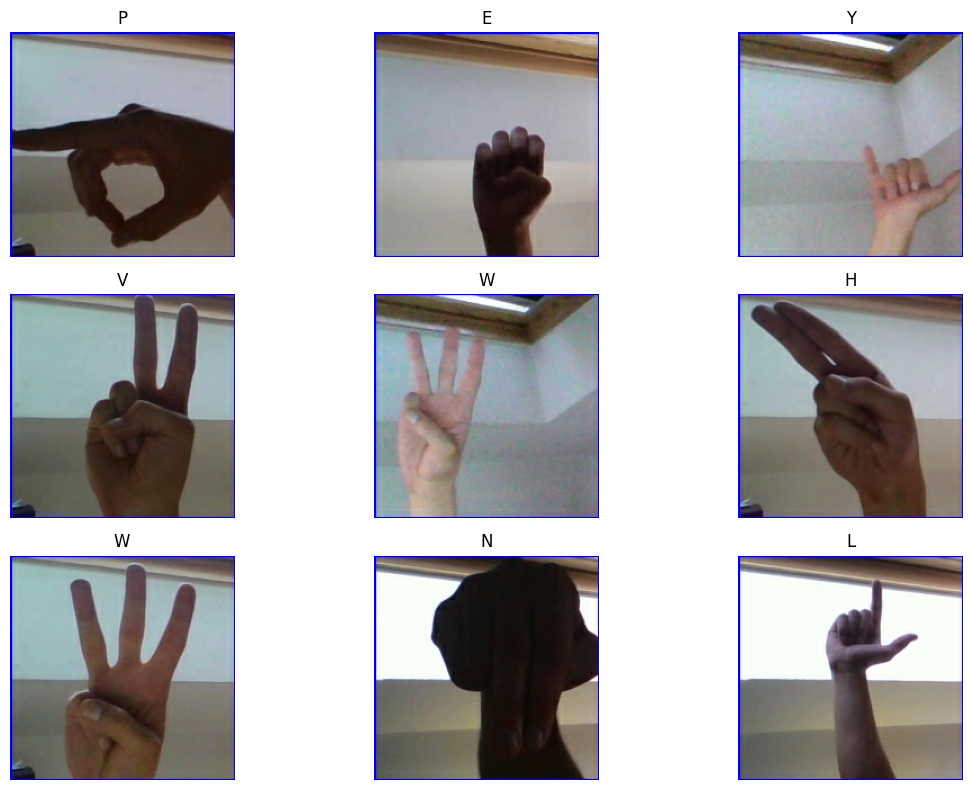

In [25]:
plt.figure(figsize=(12, 8))

for i in range(min(9, len(images))):

    ax = plt.subplot(3, 3, i + 1)

    if CHANNELS == 1:

        plt.imshow(
            images[i].numpy().squeeze(),
            cmap="gray"
        )

    else:

        plt.imshow(
            images[i].numpy()
        )

    label_id = int(
        labels[i].numpy()
    )

    plt.title(
        index_to_class[label_id]
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

## CNN design

In [26]:
model = tf.keras.Sequential(
    [
        # ====================================================
        # INPUT
        # ====================================================

        tf.keras.layers.Input(
            shape=INPUT_SHAPE,
            name="input_image"
        ),

        # ====================================================
        # CONVOLUTIONAL BLOCK 1
        # ====================================================

        tf.keras.layers.Conv2D(
            filters=32,
            kernel_size=(3, 3),
            padding="same",
            activation="relu",
            name="conv1"
        ),

        tf.keras.layers.MaxPooling2D(
            pool_size=(2, 2),
            name="pool1"
        ),

        # ====================================================
        # CONVOLUTIONAL BLOCK 2
        # ====================================================

        tf.keras.layers.Conv2D(
            filters=64,
            kernel_size=(3, 3),
            padding="same",
            activation="relu",
            name="conv2"
        ),

        tf.keras.layers.MaxPooling2D(
            pool_size=(2, 2),
            name="pool2"
        ),

        # ====================================================
        # CONVOLUTIONAL BLOCK 3
        # ====================================================

        tf.keras.layers.Conv2D(
            filters=128,
            kernel_size=(3, 3),
            padding="same",
            activation="relu",
            name="conv3"
        ),

        tf.keras.layers.MaxPooling2D(
            pool_size=(2, 2),
            name="pool3"
        ),

        # ====================================================
        # CLASSIFIER
        # ====================================================

        tf.keras.layers.GlobalAveragePooling2D(),

        tf.keras.layers.Dense(
            128,
            activation="relu",
            name="dense128"
        ),

        tf.keras.layers.Dropout(
            0.50,
            name="dropout"
        ),

        # ====================================================
        # OUTPUT
        # ====================================================

        tf.keras.layers.Dense(
            NUM_CLASSES,
            activation="softmax",
            name="output"
        )
    ],

    name="ASL_From_Scratch_CNN"
)

model.summary()

Model: "ASL_From_Scratch_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 200, 200, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 100, 100, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 100, 100, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 50, 50, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 25, 25, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense128 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 113,501 (443.36 KB)

 Trainable params: 113,501 (443.36 KB)

 Non-trainable params: 0 (0.00 B)

## Compile the network

In [27]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print("Model compiled.")

Model compiled.


## Callbacks

In [28]:
MODEL_DIR = (
    BASE_DIR / "asl_models"
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BEST_MODEL_PATH = (
    MODEL_DIR
    / f"asl_cnn_{REPRESENTATION}_best.keras"
)


callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=5,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

## Train from scratch

In [29]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/25


I0000 00:00:1790865989.019717   40575 service.cc:153] XLA service 0x7f296c006f80 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1790865989.019744   40575 service.cc:161]   StreamExecutor [0]: NVIDIA A10G, Compute Capability 8.6 (Driver: 13.2.0; Runtime: 12.8.0; Toolkit: 12.5.0; DNN: 9.10.2)
I0000 00:00:1790865989.098413   40575 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1790865989.340656   40575 cuda_dnn.cc:461] Loaded cuDNN version 91002
I0000 00:00:1790865989.393667   40575 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2103__.41
I0000 00:00:1790865996.840069   40575 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:179

  10/1904 ━━━━━━━━━━━━━━━━━━━━ 36s 19ms/step - accuracy: 0.0363 - loss: 3.3691

I0000 00:00:1790866013.619978   40575 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1903/1904 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.0743 - loss: 3.1598

I0000 00:00:1790866050.264782   40573 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2103__.41


1904/1904 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.0743 - loss: 3.1597

I0000 00:00:1790866058.264479   40575 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1790866063.720568   40573 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1790866065.306998   40573 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.



Epoch 1: val_accuracy improved from None to 0.33303, saving model to /home/ec2-user/SageMaker/asl_models/asl_cnn_raw_best.keras
1904/1904 ━━━━━━━━━━━━━━━━━━━━ 80s 29ms/step - accuracy: 0.1346 - loss: 2.8399 - val_accuracy: 0.3330 - val_loss: 2.0157 - learning_rate: 0.0010
Epoch 2/25
1903/1904 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.3193 - loss: 2.0319
Epoch 2: val_accuracy improved from 0.33303 to 0.49755, saving model to /home/ec2-user/SageMaker/asl_models/asl_cnn_raw_best.keras
1904/1904 ━━━━━━━━━━━━━━━━━━━━ 40s 21ms/step - accuracy: 0.3628 - loss: 1.8748 - val_accuracy: 0.4975 - val_loss: 1.4279 - learning_rate: 0.0010
Epoch 3/25
1902/1904 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.4727 - loss: 1.5068
Epoch 3: val_accuracy improved from 0.49755 to 0.60230, saving model to /home/ec2-user/SageMaker/asl_models/asl_cnn_raw_best.keras
1904/1904 ━━━━━━━━━━━━━━━━━━━━ 40s 21ms/step - accuracy: 0.4972 - loss: 1.4297 - val_accuracy: 0.6023 - val_loss: 1.1220 - learning_rate: 0.0

## Training graphs

In [30]:
history_df = pd.DataFrame(
    history.history
)

display(history_df)

,accuracy,loss,val_accuracy,val_loss,learning_rate
0,0.134598,2.839902,0.333027,2.015743,0.0010
1,0.362808,1.874797,0.497548,1.427932,0.0010
2,0.497225,1.429678,0.602299,1.122033,0.0010
3,0.576158,1.184962,0.730728,0.825256,0.0010
4,0.642200,0.995692,0.792261,0.647352,0.0010
5,0.690164,0.850935,0.833946,0.532207,0.0010
6,0.732135,0.738985,0.873103,0.420909,0.0010
7,0.765386,0.644637,0.906437,0.343244,0.0010
8,0.789852,0.580802,0.916552,0.284246,0.0010
9,0.811248,0.520159,0.931111,0.246120,0.0010


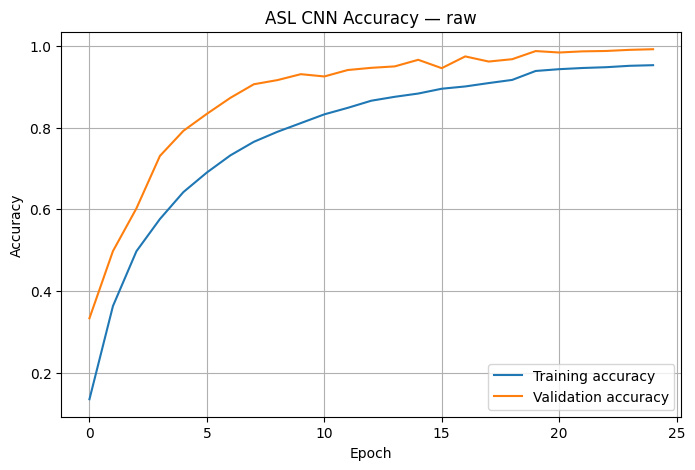

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    f"ASL CNN Accuracy — {REPRESENTATION}"
)

plt.legend()
plt.grid(True)

plt.show()

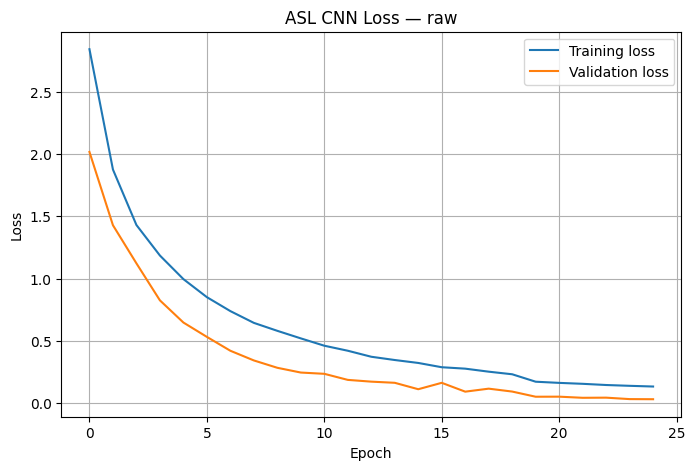

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    f"ASL CNN Loss — {REPRESENTATION}"
)

plt.legend()
plt.grid(True)

plt.show()

## Evaluate on the held-out test set

In [33]:
if BEST_MODEL_PATH.exists():

    model = tf.keras.models.load_model(
        BEST_MODEL_PATH
    )

    print(
        "Loaded best validation model:"
    )

    print(BEST_MODEL_PATH)


test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

print("\n")
print("=" * 60)
print("TEST RESULTS")
print("=" * 60)

print(
    f"Test loss: {test_loss:.4f}"
)

print(
    f"Test accuracy: "
    f"{test_accuracy:.4f}"
)

print(
    f"Test accuracy: "
    f"{test_accuracy * 100:.2f}%"
)

Loaded best validation model:
/home/ec2-user/SageMaker/asl_models/asl_cnn_raw_best.keras
408/408 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9934 - loss: 0.0324


TEST RESULTS
Test loss: 0.0324
Test accuracy: 0.9934
Test accuracy: 99.34%


## Classification report

In [34]:
y_true = []
y_pred = []


for batch_images, batch_labels in test_ds:

    probabilities = model.predict(
        batch_images,
        verbose=0
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    y_true.extend(
        batch_labels.numpy()
    )

    y_pred.extend(
        predictions
    )


print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

           A     0.9978    0.9867    0.9922       450
           B     0.9956    0.9978    0.9967       450
           C     0.9978    1.0000    0.9989       450
           D     1.0000    0.9956    0.9978       450
           E     0.9825    1.0000    0.9912       450
           F     1.0000    1.0000    1.0000       450
           G     0.9978    0.9933    0.9955       450
           H     0.9934    0.9978    0.9956       450
           I     0.9868    1.0000    0.9934       450
           J     0.9956    0.9956    0.9956       450
           K     1.0000    0.9800    0.9899       450
           L     1.0000    0.9933    0.9967       450
           M     0.9934    1.0000    0.9967       450
           N     1.0000    0.9933    0.9967       450
           O     0.9978    1.0000    0.9989       450
           P     1.0000    0.9956    0.9978       450
           Q     0.9978    0.9978    0.9978       450
           R     0.9782    

## Confusion matrix

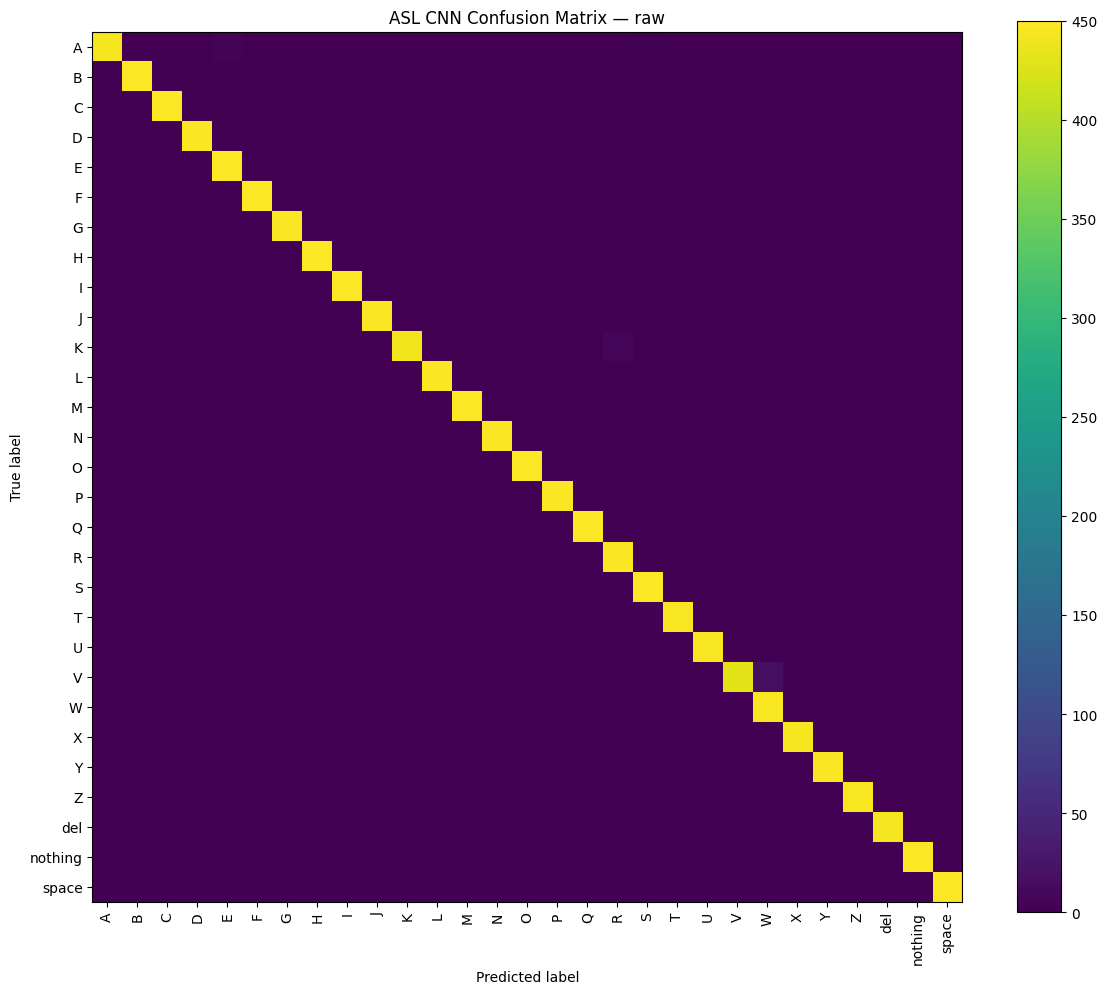

In [35]:
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(12, 10))

plt.imshow(
    cm,
    interpolation="nearest"
)

plt.title(
    f"ASL CNN Confusion Matrix — {REPRESENTATION}"
)

plt.colorbar()

plt.xticks(
    range(NUM_CLASSES),
    class_names,
    rotation=90
)

plt.yticks(
    range(NUM_CLASSES),
    class_names
)

plt.xlabel("Predicted label")
plt.ylabel("True label")

plt.tight_layout()

plt.show()

## Save the model

In [36]:
FINAL_MODEL_PATH = (
    MODEL_DIR
    / f"asl_cnn_{REPRESENTATION}_final.keras"
)

model.save(
    FINAL_MODEL_PATH
)

print(
    "Model saved to:"
)

print(
    FINAL_MODEL_PATH
)

Model saved to:
/home/ec2-user/SageMaker/asl_models/asl_cnn_raw_final.keras


In [37]:
HISTORY_PATH = (
    MODEL_DIR
    / f"training_history_{REPRESENTATION}.csv"
)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)

print(
    "Training history saved to:"
)

print(
    HISTORY_PATH
)

Training history saved to:
/home/ec2-user/SageMaker/asl_models/training_history_raw.csv


## S3 upload

In [38]:
import boto3

s3 = boto3.client("s3")

# Replace with your actual bucket
BUCKET = "YOUR_BUCKET"

In [39]:
s3.upload_file(
    str(FINAL_MODEL_PATH),
    BUCKET,
    f"models/asl_cnn_{REPRESENTATION}_final.keras"
)

s3.upload_file(
    str(HISTORY_PATH),
    BUCKET,
    f"models/training_history_{REPRESENTATION}.csv"
)

print("Model and training history uploaded to S3.")

Model and training history uploaded to S3.


In [40]:
s3.upload_file(
    str(BEST_MODEL_PATH),
    BUCKET,
    f"models/asl_cnn_{REPRESENTATION}_best.keras"
)

print("Best model uploaded to S3.")

Best model uploaded to S3.
